In [1]:
import pandas as pd
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
df_timeseries = pd.read_csv(
    r"C:\Users\andre\Desktop\VS Code datafiler\Data analysis files\openpowerlifting-2020-09-06.csv", index_col='Date', parse_dates=True
)
print(df_timeseries.head())

C:\Users\andre\AppData\Local\Temp\ipykernel_12428\2077293843.py:6: DtypeWarning: Columns (34: ParentFederation, 37: MeetState) have mixed types. Specify dtype option on import or set low_memory=False.
  df_timeseries = pd.read_csv(


                          Name Sex Event   Equipment   Age AgeClass  \
Date                                                                  
2019-04-06      Tucker Sanders   M     B  Single-ply  15.0    13-15   
2019-04-06       Xander Womack   M     B  Single-ply  14.0    13-15   
2019-04-06  Michael Womack III   M     B  Single-ply  16.0    16-17   
2019-04-06      Logan McCurley   M     B  Single-ply  16.0    16-17   
2019-04-06       Emily Jondron   F     B  Single-ply  21.0    20-23   

           BirthYearClass       Division  BodyweightKg WeightClassKg  ...  \
Date                                                                  ...   
2019-04-06          14-18     Teen 14-15          52.0            52  ...   
2019-04-06          14-18     Teen 14-15         100.0           100  ...   
2019-04-06          14-18     Teen 16-17          67.5          67.5  ...   
2019-04-06          14-18     Teen 16-17          75.0            75  ...   
2019-04-06          19-23  Juniors 20-25

In [2]:
df_timeseries.loc[df_timeseries["Sex"]== "M","BodyweightGroupMen"] = pd.cut(
    df_timeseries.loc[df_timeseries["Sex"]== "M","BodyweightKg"],
    bins=[59, 66, 74, 83, 93, 105, 120, float("inf")],
    labels=["59-65kg", "66-73kg", "74-82kg", "83-92kg", "93-104kg", "105-119kg", "120+" ]
)

df_timeseries.loc[df_timeseries["Sex"]== "F","BodyweightGroupWomen"] = pd.cut(
    df_timeseries.loc[df_timeseries["Sex"]== "F","BodyweightKg"],
    bins=[47, 52, 57, 63, 69, 76, 84, float("inf")],
    labels=["47-51kg", "52-56kg", "57-62kg", "63-68kg", "69-75g", "76-83", "84+" ]
)

df_timeseries = df_timeseries.loc[df_timeseries['Event'] == 'SBD'].copy()

df_timeseries = df_timeseries.loc[df_timeseries['Tested'] == 'Yes'].copy()


def top1000_mean(x):
    return x.nlargest(1000).mean()
#Bedste løft per land tager udfra gennemsnit af de 1000 bedste løft i KG i Testet SBD 
top_1000_each_year = (
    df_timeseries
    .groupby([pd.Grouper(freq='YE'), 'MeetCountry'])['TotalKg']
    .apply(top1000_mean)
    .reset_index(name='Top1000Mean')
)

result = top_1000_each_year.sort_values(
    ['Date', 'Top1000Mean'],
    ascending=[True, False]
)

top_1000_each_year['Rank'] = top_1000_each_year.groupby('Date')['Top1000Mean'].rank(ascending=False, method='min').astype(int)

print(top_1000_each_year)

#__________________________________________________________
def top10_mean(x):
    return x.nlargest(10).mean()
#Bedste løft per land tager udfra gennemsnit af de 10 bedste løft i KG i Testet SBD 
top_10_each_year = (
    df_timeseries
    .groupby([pd.Grouper(freq='YE'), 'MeetCountry'])['TotalKg']
    .apply(top10_mean)
    .reset_index(name='Top5Mean')
)


top_10_each_year = top_10_each_year.sort_values(
    ['Date', 'Top5Mean'],
    ascending=[True, False]
)

top_10_each_year['Rank'] = top_10_each_year.groupby('Date')['Top5Mean'].rank(ascending=False, method='min').astype(int)

print(top_10_each_year)

           Date        MeetCountry  Top1000Mean  Rank
0    1964-12-31                USA   563.210952     1
1    1966-12-31                 UK   577.368421     1
2    1967-12-31                 UK   577.500000     1
3    1968-12-31                 UK   596.176471     1
4    1969-12-31                 UK   583.437500     1
...         ...                ...          ...   ...
1122 2020-12-31             Turkey   466.156463    15
1123 2020-12-31                 UK   417.106061    27
1124 2020-12-31  US Virgin Islands   471.904762    13
1125 2020-12-31                USA   748.309920     1
1126 2020-12-31              Wales   408.636364    28

[1127 rows x 4 columns]
           Date        MeetCountry  Top5Mean  Rank
0    1964-12-31                USA   663.379     1
1    1966-12-31                 UK   662.750     1
2    1967-12-31                 UK   682.000     1
3    1968-12-31                 UK   662.500     1
4    1969-12-31                 UK   643.000     1
...         ...      

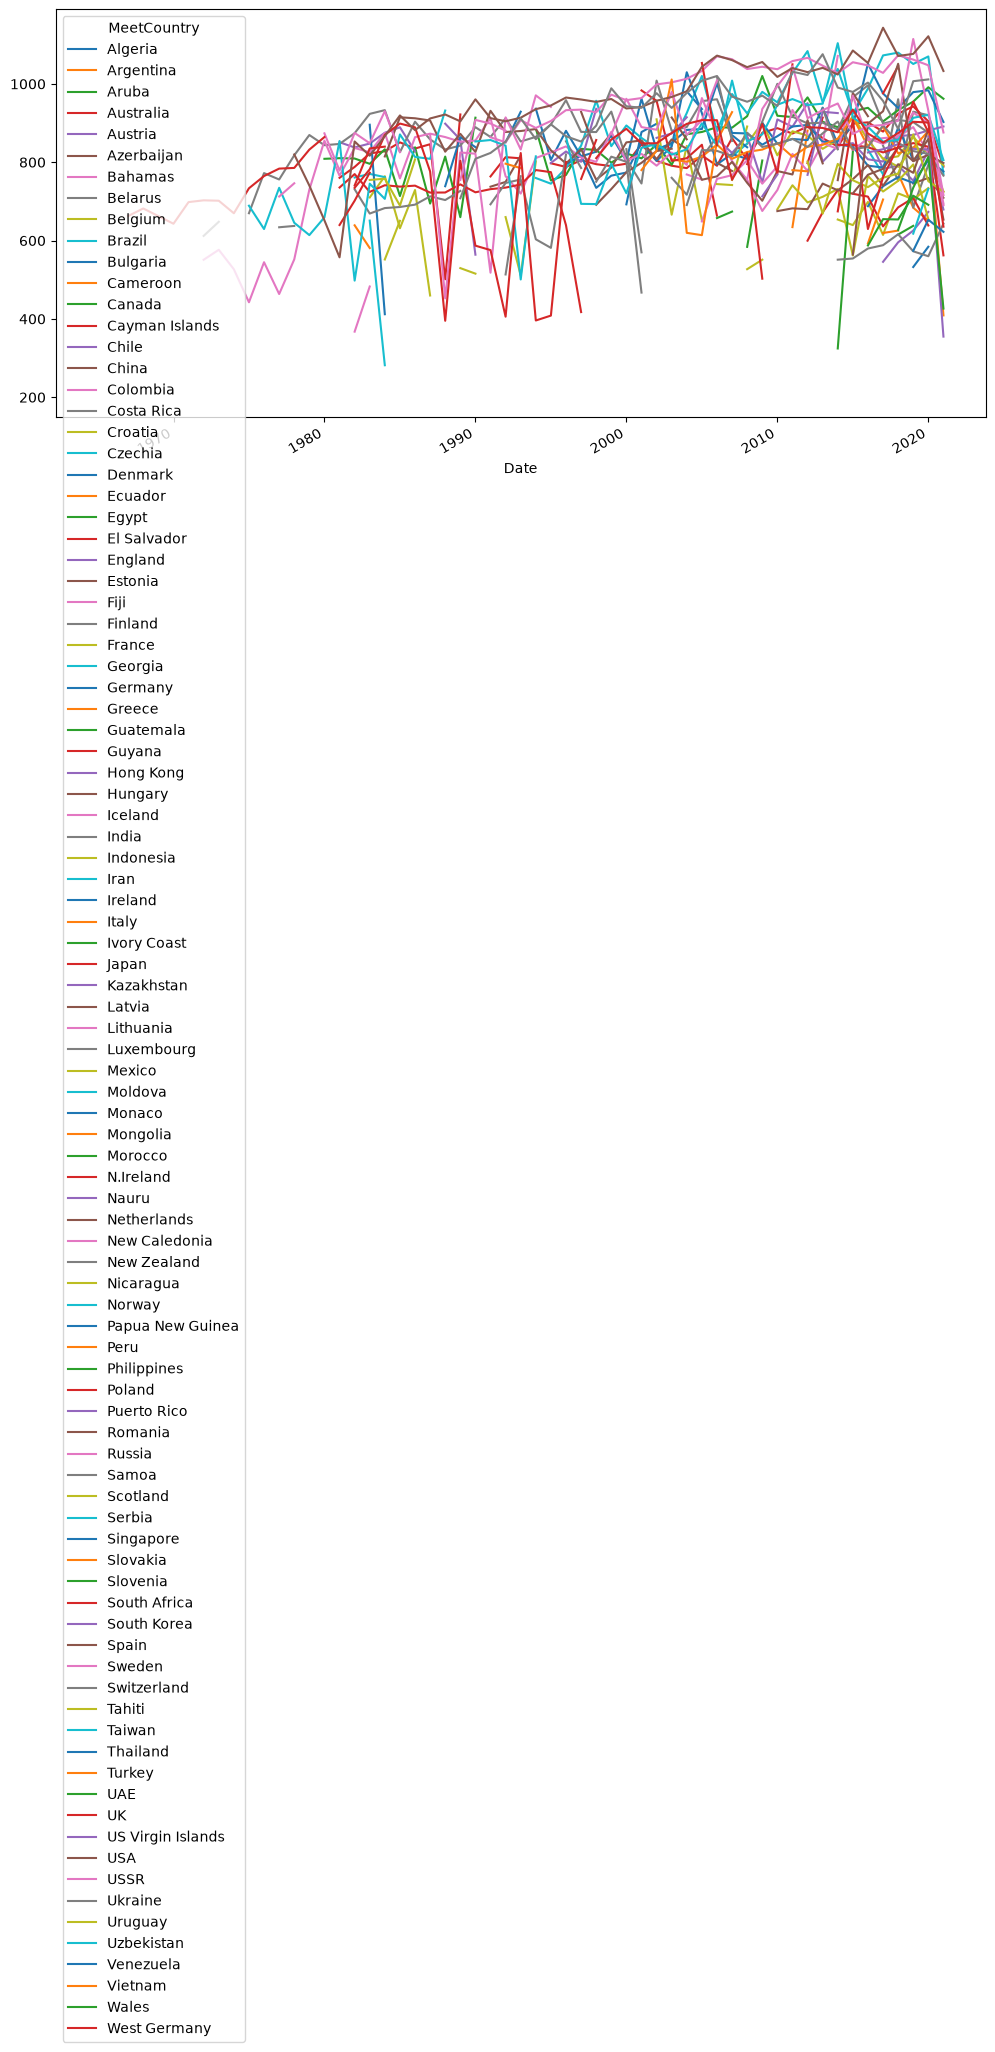

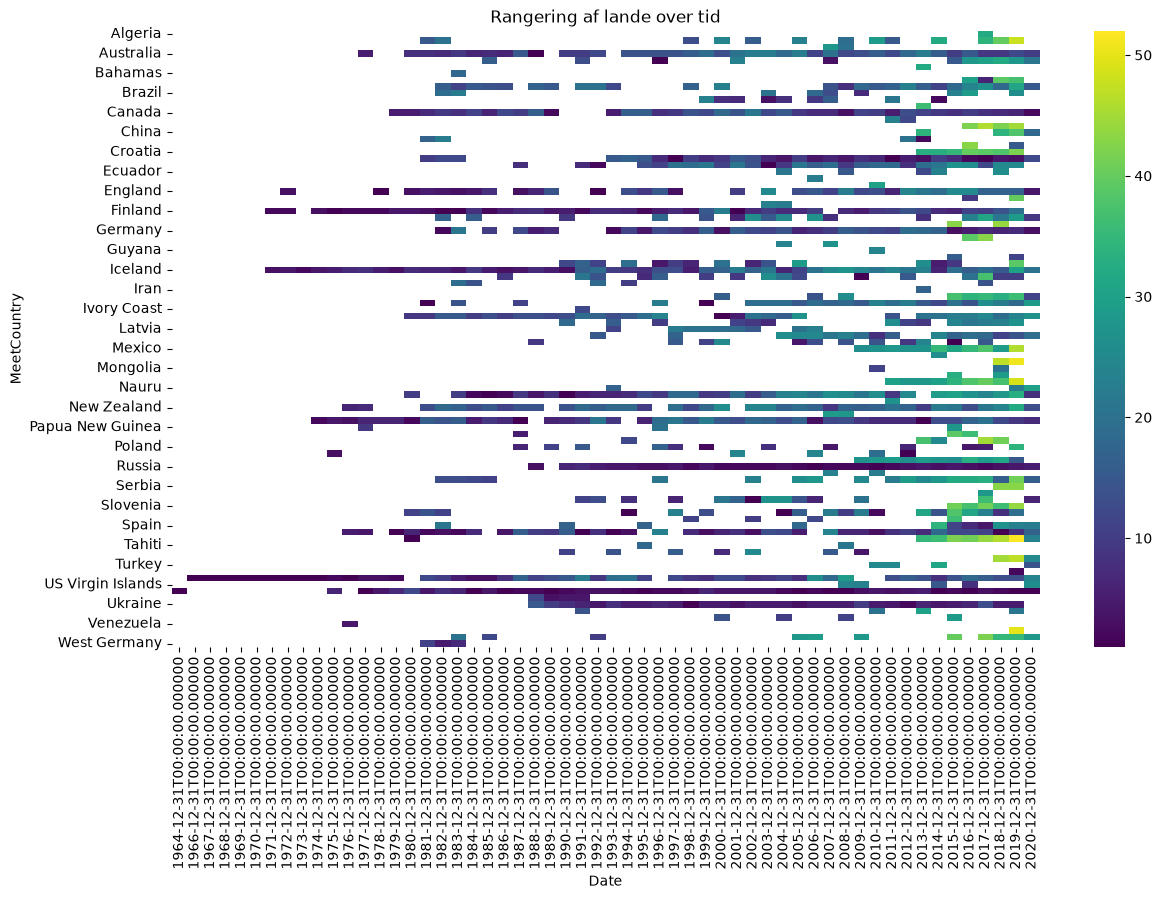

In [4]:
plot_data =(top_10_each_year.groupby(['Date','MeetCountry'])['Top5Mean'].mean().unstack())

fig, ax = plt.subplots(figsize=(12, 6))

plot_data.plot(ax=ax)

plt.show()




heatmap_data= top_10_each_year.pivot(index='MeetCountry', columns='Date', values='Rank')

plt.figure(figsize=(14, 8))

sns.heatmap(heatmap_data, annot=False, cmap='viridis')

plt.title('Rangering af lande over tid')
plt.show()



In [50]:
def top3(x):
    if len (x) < 3:
        return np.nan
    return x.nlargest(3).mean()



#Bedste løft taget per år per land fra gennemsnitet af de 3 største goodlift (Ikke nødvendigvis sorteret per løfter)
Country_weightclass_perf = (
    df_timeseries
    .groupby([pd.Grouper(freq='YE'),'MeetCountry', 'BodyweightGroupMen'],observed=True)['Goodlift']
    .apply(top3)
    .dropna()
    .reset_index()
)

#__________________________________________________________

#Sørge for at alle lande har minimum 3 løftere per vægtkategori
valid_country_years = (
    Country_weightclass_perf
    .groupby(['Date', 'MeetCountry'])['BodyweightGroupMen']
    .nunique()
)

valid_country_years = valid_country_years[
    valid_country_years == 7
]

valid_country_years = (
    valid_country_years
    .reset_index()[['Date', 'MeetCountry']]
)

Country_weightclass_perf = (
    Country_weightclass_perf
    .merge(
        valid_country_years,
        on=['Date', 'MeetCountry'],
        how='inner'
    )
)
#__________________________________________________________

#Gennemsnitlige Goodlift per vægt klasse per år per land  
country_scores = (
    Country_weightclass_perf
    .groupby([
        'Date',
        'MeetCountry'
    ])[['Goodlift']]
    .mean()
    .reset_index()
   
)

def top5(x):
    return x.nlargest(5, 'Goodlift')

#De 5 bedste lande udfra gennemsnit af goodlift af landets 3 bedste løftere per år per vægtklasse
country_scores_top5_Country_by_year = (
    country_scores
    .groupby('Date')
    .apply(top5)
    .reset_index()
)



In [32]:

country_scores_top5_Country_by_year_reg = country_scores_top5_Country_by_year[(country_scores_top5_Country_by_year['MeetCountry'] == 'Russia') | (country_scores_top5_Country_by_year['MeetCountry']=='USA') ]

latest_date = country_scores_top5_Country_by_year_reg['Date'].max()
start = latest_date - pd.Timedelta(days=10672)

country_scores_top5_Country_by_year_reg= country_scores_top5_Country_by_year_reg[country_scores_top5_Country_by_year_reg['Date'] >= start]

country_scores_top5_Country_by_year_reg = country_scores_top5_Country_by_year_reg.pivot(
    index='Date',
    columns='MeetCountry',
    values='Goodlift'
)

print(country_scores_top5_Country_by_year_reg)

MeetCountry      Russia         USA
Date                               
1991-12-31    85.617619   89.240476
1992-12-31    89.700000   89.169524
1993-12-31    89.553333   90.537619
1994-12-31    89.915714   91.475238
1995-12-31    92.436667   92.043333
1996-12-31    91.493810   92.490952
1997-12-31    91.993810   91.515238
1998-12-31    94.183810   92.464762
1999-12-31    95.018571   94.037619
2000-12-31    95.728571   93.986667
2001-12-31    97.199048   93.444286
2002-12-31    97.561429   93.915714
2003-12-31    99.658095   94.253333
2004-12-31   102.510476   96.428571
2005-12-31   104.427619  103.326667
2006-12-31   104.792857   98.158095
2007-12-31   102.725238   97.443333
2008-12-31   103.912381   97.630952
2009-12-31   102.834762   98.270000
2010-12-31   102.416667   98.551905
2011-12-31   103.150952   98.908095
2012-12-31   103.389524   99.471429
2013-12-31   102.730000  101.580476
2014-12-31   104.317619  106.837143
2015-12-31   103.221905  105.249048
2016-12-31   104.560476  109

In [33]:
returns = (np.log(country_scores_top5_Country_by_year_reg).diff()).dropna()
print(returns)

MeetCountry    Russia       USA
Date                           
1992-12-31   0.046580 -0.000795
1993-12-31  -0.001636  0.015226
1994-12-31   0.004038  0.010303
1995-12-31   0.027651  0.006191
1996-12-31  -0.010252  0.004851
1997-12-31   0.005450 -0.010605
1998-12-31   0.023527  0.010322
1999-12-31   0.008824  0.016867
2000-12-31   0.007444 -0.000542
2001-12-31   0.015244 -0.005788
2002-12-31   0.003721  0.005032
2003-12-31   0.021263  0.003588
2004-12-31   0.028220  0.022816
2005-12-31   0.018529  0.069093
2006-12-31   0.003491 -0.051316
2007-12-31  -0.019928 -0.007308
2008-12-31   0.011490  0.001924
2009-12-31  -0.010425  0.006524
2010-12-31  -0.004074  0.002865
2011-12-31   0.007144  0.003608
2012-12-31   0.002310  0.005679
2013-12-31  -0.006399  0.020981
2014-12-31   0.015336  0.050454
2015-12-31  -0.010559 -0.014976
2016-12-31   0.012885  0.040060
2017-12-31   0.001802 -0.004129
2018-12-31  -0.011255  0.000384
2019-12-31   0.012709  0.016272
2020-12-31  -0.026700 -0.033199


[0.52535192 0.00316189]


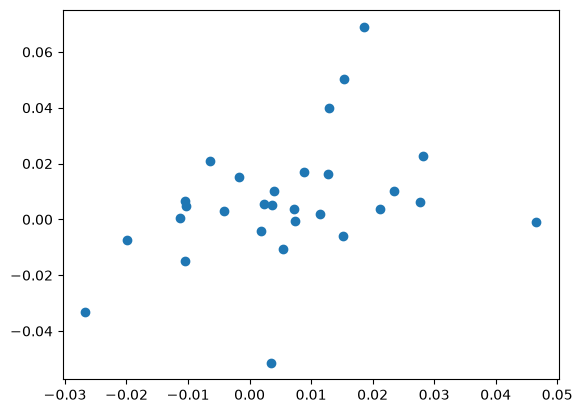

In [39]:
returns.corr()
plt.scatter(x=returns['Russia'], y=returns['USA']);
reg = np.polyfit(returns['Russia'], returns['USA'], deg= 1)
print(reg)

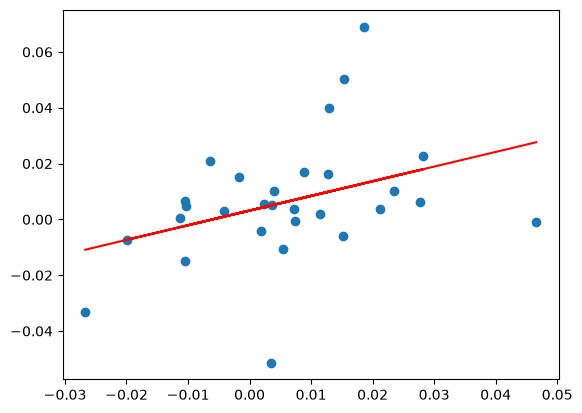

In [38]:
trend= np.polyval(reg, returns['Russia'])
plt.scatter(returns['Russia'], returns['USA'])
plt.plot(returns['Russia'], trend, 'r');

In [52]:

country_scores_top5_Country_by_year_reg = country_scores_top5_Country_by_year[(country_scores_top5_Country_by_year['MeetCountry']=='Russia') ]

latest_date = country_scores_top5_Country_by_year_reg['Date'].max()
start = latest_date - pd.Timedelta(days=10672)
country_scores_top5_Country_by_year_reg= country_scores_top5_Country_by_year_reg[country_scores_top5_Country_by_year_reg['Date'] >= start]

time = np.arange(1, len(country_scores_top5_Country_by_year_reg)+1)
country_scores_top5_Country_by_year_reg['time']= time 
country_scores_top5_Country_by_year_reg= country_scores_top5_Country_by_year_reg[['time', 'Goodlift']]
print(country_scores_top5_Country_by_year_reg)

     time    Goodlift
66      1   85.617619
68      2   89.700000
75      3   89.553333
80      4   89.915714
83      5   92.436667
90      6   91.493810
94      7   91.993810
98      8   94.183810
103     9   95.018571
108    10   95.728571
113    11   97.199048
118    12   97.561429
122    13   99.658095
128    14  102.510476
132    15  104.427619
137    16  104.792857
142    17  102.725238
147    18  103.912381
153    19  102.834762
157    20  102.416667
163    21  103.150952
168    22  103.389524
173    23  102.730000
178    24  104.317619
185    25  103.221905
188    26  104.560476
195    27  104.749048
201    28  103.576667
205    29  104.901429
208    30  102.137619


In [53]:
reg2= np.polyfit(country_scores_top5_Country_by_year_reg['time'], country_scores_top5_Country_by_year_reg['Goodlift'], deg=1)
reg2

array([ 0.59911489, 89.72757635])

In [6]:
from collections import Counter
counts = Counter(country_scores_top5_Country_by_year['MeetCountry'])
print(counts)

Counter({'USA': 39, 'Russia': 31, 'Finland': 18, 'Ukraine': 17, 'Sweden': 14, 'Canada': 10, 'Czechia': 9, 'England': 7, 'Germany': 7, 'Norway': 6, 'UK': 5, 'South Africa': 4, 'Iceland': 3, 'Australia': 3, 'Netherlands': 3, 'Denmark': 3, 'Luxembourg': 3, 'USSR': 3, 'Poland': 3, 'Italy': 2, 'India': 2, 'Austria': 2, 'Hungary': 2, 'Japan': 2, 'Bulgaria': 2, 'Switzerland': 1, 'West Germany': 1, 'Slovakia': 1, 'Brazil': 1, 'Puerto Rico': 1, 'Kazakhstan': 1, 'Estonia': 1, 'Belarus': 1, 'Lithuania': 1, 'UAE': 1, 'France': 1, 'Ireland': 1})


In [6]:
print(Country_weightclass_perf)
print(country_scores)
print(country_scores_top5_Country_by_year.tail(30))

           Date MeetCountry BodyweightGroupMen    Goodlift
0    1976-12-31          UK            59-65kg   83.043333
1    1976-12-31          UK            66-73kg   92.493333
2    1976-12-31          UK            74-82kg  109.800000
3    1976-12-31          UK            83-92kg   90.016667
4    1976-12-31          UK           93-104kg   99.326667
...         ...         ...                ...         ...
5364 2020-12-31         USA            74-82kg  110.946667
5365 2020-12-31         USA            83-92kg  111.093333
5366 2020-12-31         USA           93-104kg  108.690000
5367 2020-12-31         USA          105-119kg  104.143333
5368 2020-12-31         USA               120+  105.780000

[5369 rows x 4 columns]
          Date MeetCountry    Goodlift
0   1976-12-31          UK   92.392619
1   1977-12-31         USA   91.704762
2   1978-12-31     England   84.815238
3   1979-12-31      Canada   80.686190
4   1979-12-31     Finland   80.509048
..         ...         ...       

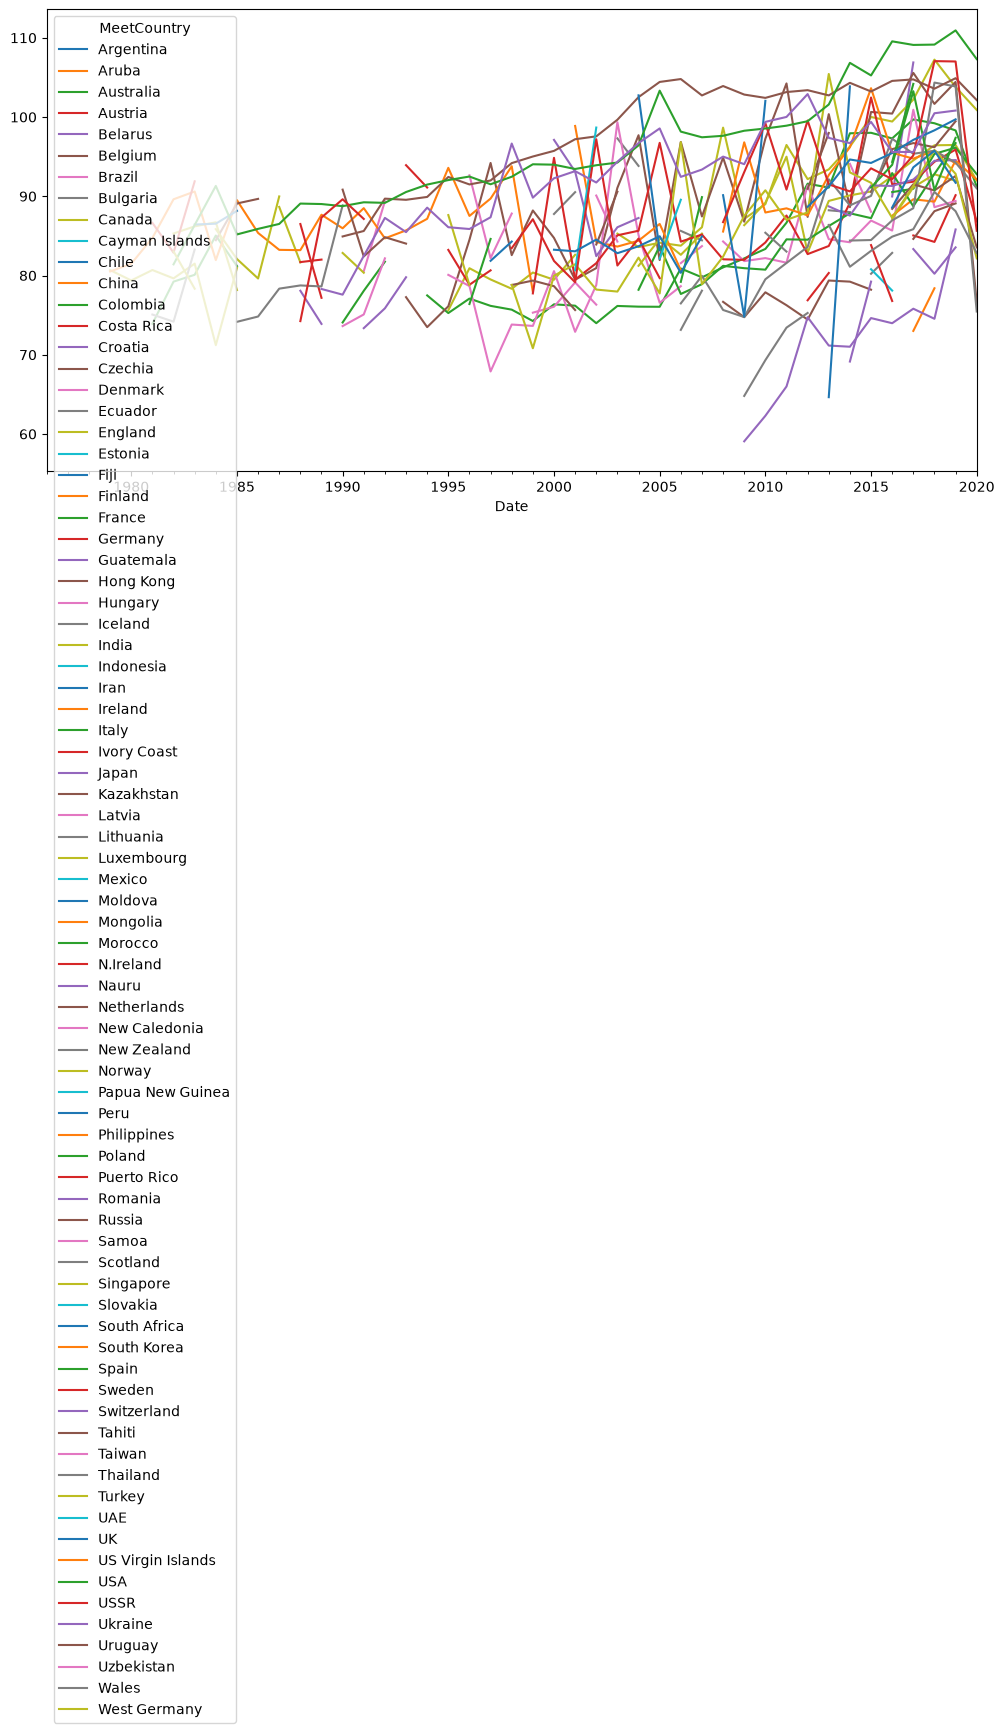

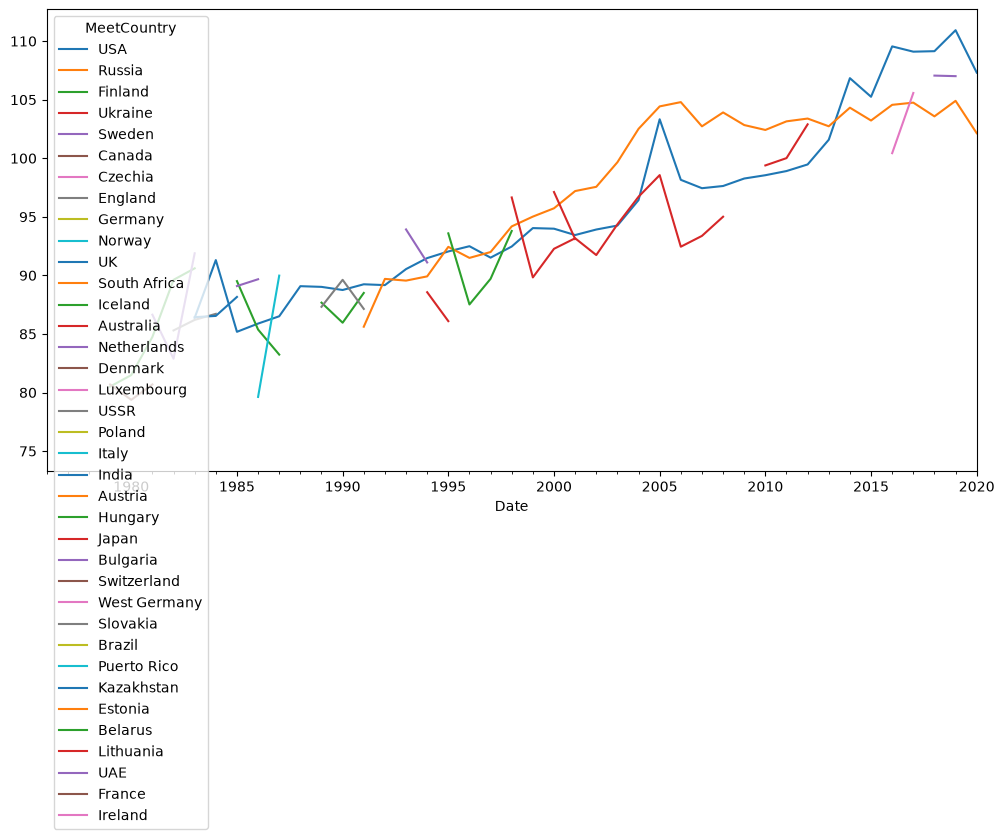

In [8]:
plot_data2 =(country_scores.groupby(['Date','MeetCountry'])['Goodlift'].mean().unstack())
fig, ax = plt.subplots(figsize=(12, 6))
plot_data2.plot(ax=ax)

plt.show()



country_order = (
    country_scores_top5_Country_by_year['MeetCountry']
    .value_counts()
    .index
)

plot_data3 =(country_scores_top5_Country_by_year.groupby(['Date','MeetCountry'])['Goodlift'].mean().unstack())
plot_data3 = plot_data3[country_order]

plot_data3.plot(figsize=(12, 6))

plt.show()


In [2]:
import pandas as pd
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
df_timeseries = pd.read_csv(
    r"C:\Users\andre\Desktop\VS Code datafiler\Data analysis files\openpowerlifting-2020-09-06.csv", index_col='Date', parse_dates=True
)
print(df_timeseries.head())


#_______________________________________________________
df_timeseries.loc[df_timeseries["Sex"]== "M","BodyweightGroupMen"] = pd.cut(
    df_timeseries.loc[df_timeseries["Sex"]== "M","BodyweightKg"],
    bins=[59, 66, 74, 83, 93, 105, 120, float("inf")],
    labels=["59-65kg", "66-73kg", "74-82kg", "83-92kg", "93-104kg", "105-119kg", "120+" ]
)

df_timeseries.loc[df_timeseries["Sex"]== "F","BodyweightGroupWomen"] = pd.cut(
    df_timeseries.loc[df_timeseries["Sex"]== "F","BodyweightKg"],
    bins=[47, 52, 57, 63, 69, 76, 84, float("inf")],
    labels=["47-51kg", "52-56kg", "57-62kg", "63-68kg", "69-75g", "76-83", "84+" ]
)

df_timeseries = df_timeseries.loc[df_timeseries['Event'] == 'SBD'].copy()

df_timeseries = df_timeseries.loc[df_timeseries['Tested'] == 'Yes'].copy()
#_______________________________________________________
df_timeseries_func = df_timeseries

valid_country_years_func = (
    df_timeseries_func
    .groupby(['Date', 'MeetCountry'])['BodyweightGroupMen']
    .nunique()
)

valid_country_years_func = valid_country_years_func[
    valid_country_years_func == 7
]

valid_country_years_func = (
    valid_country_years_func
    .reset_index()[['Date', 'MeetCountry']]
)

C:\Users\andre\AppData\Local\Temp\ipykernel_8824\2825903831.py:6: DtypeWarning: Columns (34: ParentFederation, 37: MeetState) have mixed types. Specify dtype option on import or set low_memory=False.
  df_timeseries = pd.read_csv(


                          Name Sex Event   Equipment   Age AgeClass  \
Date                                                                  
2019-04-06      Tucker Sanders   M     B  Single-ply  15.0    13-15   
2019-04-06       Xander Womack   M     B  Single-ply  14.0    13-15   
2019-04-06  Michael Womack III   M     B  Single-ply  16.0    16-17   
2019-04-06      Logan McCurley   M     B  Single-ply  16.0    16-17   
2019-04-06       Emily Jondron   F     B  Single-ply  21.0    20-23   

           BirthYearClass       Division  BodyweightKg WeightClassKg  ...  \
Date                                                                  ...   
2019-04-06          14-18     Teen 14-15          52.0            52  ...   
2019-04-06          14-18     Teen 14-15         100.0           100  ...   
2019-04-06          14-18     Teen 16-17          67.5          67.5  ...   
2019-04-06          14-18     Teen 16-17          75.0            75  ...   
2019-04-06          19-23  Juniors 20-25

In [3]:
def Top_Countries_By_WeightClass_And_Year(Points, ClassSex, AthleteAMT, TopCountriesShown):

    def top3(x):
        if len (x) < AthleteAMT:
            return np.nan
        return x.nlargest(AthleteAMT).mean()

    def top5(x):
        return x.nlargest(TopCountriesShown, Points)


    Country_weightclass_perf_func = (
        df_timeseries_func
        .groupby([pd.Grouper(freq='YE'),'MeetCountry', ClassSex],observed=True)[Points]
        .apply(top3)
        .dropna()
        .reset_index()
    )

    country_scores = (
        Country_weightclass_perf_func
        .groupby([
            'Date',
            'MeetCountry'
        ])[[Points]]
        .mean()
        .reset_index()
    )

    country_scores_top5_Country_by_year = (
        country_scores
        .groupby('Date')
        .apply(top5)
        .reset_index()
    )

    return {
        'Country_weightclass_perf_func': Country_weightclass_perf_func,
        'country_scores': country_scores,
        'country_scores_top5_Country_by_year': country_scores_top5_Country_by_year
    }

In [4]:
Top_Countries_By_WeightClass_And_Year("TotalKg",'BodyweightGroupWomen', 10, 3)

{'Country_weightclass_perf_func':            Date MeetCountry BodyweightGroupWomen     TotalKg
 0    1977-12-31   Australia              57-62kg  212.500000
 1    1980-12-31       Japan              47-51kg  235.250000
 2    1980-12-31         USA              47-51kg  275.750000
 3    1980-12-31         USA              57-62kg  315.833333
 4    1981-12-31     England              52-56kg  234.750000
 ...         ...         ...                  ...         ...
 2439 2020-12-31         USA              57-62kg  474.890000
 2440 2020-12-31         USA              63-68kg  466.259000
 2441 2020-12-31         USA               69-75g  492.327000
 2442 2020-12-31         USA                76-83  514.949000
 2443 2020-12-31         USA                  84+  590.249000
 
 [2444 rows x 4 columns],
 'country_scores':           Date MeetCountry     TotalKg
 0   1977-12-31   Australia  212.500000
 1   1980-12-31       Japan  235.250000
 2   1980-12-31         USA  295.791667
 3   1981-12-31  